# =====================================================================
# COURSE CONTENT METADATA: ANA500 MICRO-PROJECT 1
# =====================================================================
# Project Focus: Data Preparation & Profiling of Spotify Tracks
# Data Scientist: Chaianna Roldan
# Project Repository:
# =====================================================================


In [8]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv(r"dataset.csv")
# View structural shape
print("--- RAW DATA STRUCTURAL SHAPE PROFILE ---")
print(f"Total Logged Records: {df.shape[0]} Rows | Feature Channels: {df.shape[1]} Columns\n")

--- RAW DATA STRUCTURAL SHAPE PROFILE ---
Total Logged Records: 114000 Rows | Feature Channels: 21 Columns



In [9]:
# Structure
print("--- SCHEMA PROFILE & ENTRY COUNTS ---")
df.info()

--- SCHEMA PROFILE & ENTRY COUNTS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-n

In [10]:
# Summary statistics
print("\n--- BASELINE STRUCTURAL SUMMARY STATISTICS ---")
df.describe()


--- BASELINE STRUCTURAL SUMMARY STATISTICS ---


,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


Workspace Sanitization and Row Deduplication

Real-world datasets frequently contain index artifacts and row duplicates that consume processing memory and introduce modeling bias. In this section, we drop the redundant Unnamed: 0 column created during file serialization. We then isolate the unique tracking feature (track_id) to audit and remove duplicate entries across playlist repetitions, ensuring data independence.

In [11]:
# Remove 'Unnamed: 0' [created from the CSV conversion]
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
    print("✓ Successfully dropped redundant index column 'Unnamed: 0'.")

✓ Successfully dropped redundant index column 'Unnamed: 0'.


In [12]:
# Use unique identifier subset matching to count duplicate records across track entries
duplicate_mask_count = df.duplicated(subset=['track_id']).sum()
print(f"Identified Duplicate Track ID Instances: {duplicate_mask_count}")

Identified Duplicate Track ID Instances: 24259


In [13]:
# Drop duplicate track rows
df.drop_duplicates(subset=['track_id'], keep='first', inplace=True)
print(f"✓ Deduplication complete. Post-cleaning shape boundary: {df.shape}")

✓ Deduplication complete. Post-cleaning shape boundary: (89741, 20)


In [14]:
# Track and sum missing observation flags across all dataset features
print("--- PRE-IMPUTATION NULL VALUE PROFILE ---")
print(df.isnull().sum())

--- PRE-IMPUTATION NULL VALUE PROFILE ---
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


Categorical Imputation Strategy

The null-vector check reveals a sparse data omission pattern: the textual variables artists, album_name, and track_name are each missing exactly one observation record out of the 114,000 matrix footprint. Dropping these rows entirely would result in an unnecessary loss of perfectly valid quantitative metrics across columns like popularity, danceability, and energy.To preserve maximum row completeness, the code below executes a direct vector column assignment loop. It overwrites missing cells with a standard fallback placeholder string ('Unknown'). This resolves all null flags within the text channels without triggering chained-assignment warnings.

In [16]:
# Loop for Sparse Character Imputation
text_null_targets = ['artists', 'album_name', 'track_name']

for column_target in text_null_targets:
    # Explicitly overwrite the column directly to avoid the chained-assignment warning
    df[column_target] = df[column_target].fillna('Unknown')

print("\n✓ Sparse character anomalies resolved via explicit vector imputation.")



✓ Sparse character anomalies resolved via explicit vector imputation.


Feature Modification, Matrix Optimization, and High-Performance Profiling

Following deduplication and text imputation procedures, a continuous variable adjustment was applied to improve feature interpretability:

- Duration Scale Transformation: Track lengths are converted from raw integer milliseconds (duration_ms) to continuous decimal minutes (duration_min) via a vectorized divisor scale of 60,000, allowing us to drop the unneeded baseline column.
- NumPy Vector Computation: To formally terminate the data preparation stage at Step 2. Prepare, key targeted metrics are converted from Pandas Series into high-performance NumPy arrays (popularity_vector and energy_vector) to calculate true baseline parameters.

In [17]:
# Transform millisecond durations to continuous minutes
df['duration_min'] = df['duration_ms'] / 60000
df.drop(columns=['duration_ms'], inplace=True)

# Convert Pandas series directly into high-performance NumPy arrays
popularity_vector = df['popularity'].to_numpy()
energy_vector = df['energy'].to_numpy()

# Calculate definitive distribution boundaries using NumPy vectors
pop_median = np.median(popularity_vector)
energy_90th = np.percentile(energy_vector, 90)

print("--- CLEANED SUMMARY PROFILE ---")
print(f"Final Cleaned Dataset Dimensions: {df.shape}")
print(f"Median Track Popularity Score   : {pop_median}")
print(f"90th Percentile Energy Cutoff   : {energy_90th:.3f}")


--- CLEANED SUMMARY PROFILE ---
Final Cleaned Dataset Dimensions: (89741, 20)
Median Track Popularity Score   : 33.0
90th Percentile Energy Cutoff   : 0.942


✓ Cleaned dataset successfully saved to 'spotify_tracks.csv'.


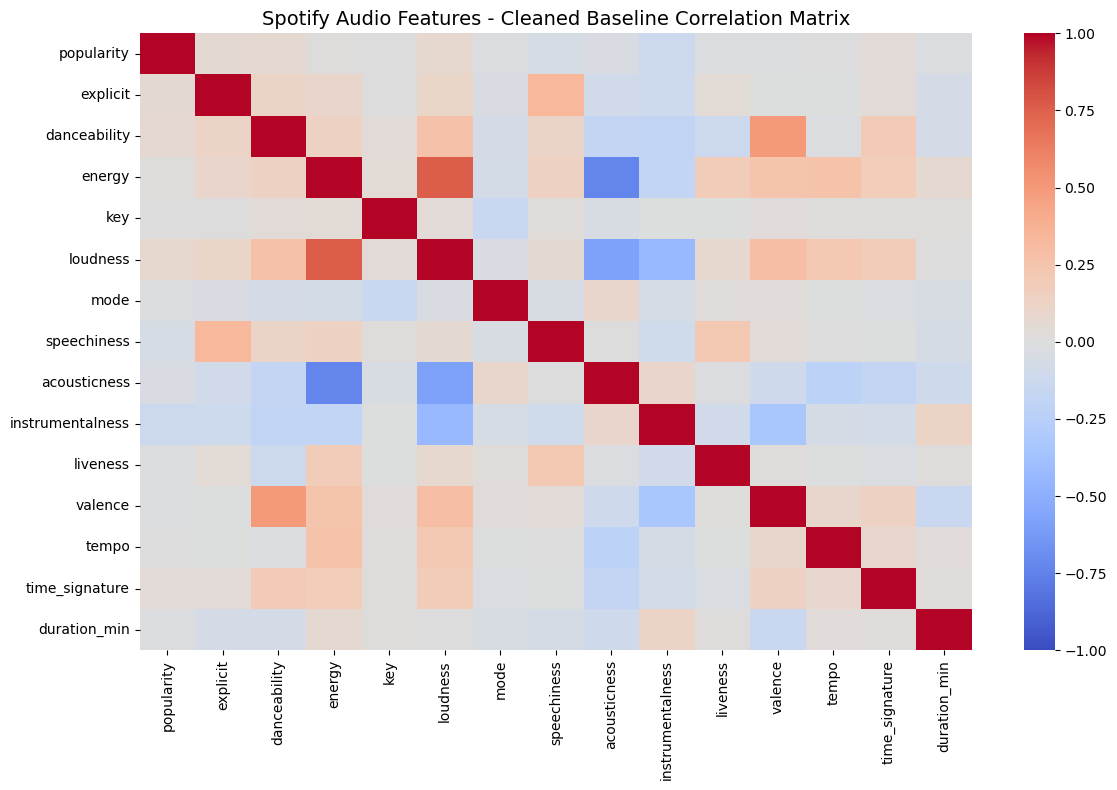

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Save the Cleaned DataFrame
# index=False ensures the row numbers do not create another 'Unnamed' column
df.to_csv("spotify_tracks.csv", index=False)
print("✓ Cleaned dataset successfully saved to 'spotify_tracks.csv'.")

# Generate Correlation Matrix Heatmap
plt.figure(figsize=(12, 8))

# numeric_only=True prevents errors with string columns like 'artists'
correlation_matrix = df.corr(numeric_only=True)

# Plotting using coolwarm styling rules
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)

plt.title("Spotify Audio Features - Cleaned Baseline Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()


The matrix reveals a prominent positive relationship between energy and loudness, alongside an expected strong negative relationship between acousticness and electronic energy. Crucially, the target variable popularity displays near-neutral correlation values across all individual structural audio attributes. This statistical isolation indicates that popularity is not governed by a single isolated variable, providing empirical support for our alternative hypothesis which tests high-tier percentile combinations of variables rather than single linear features.